1. IMPORT LIBRARY

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

2. LOAD DATASET

In [25]:
file_path = "dataset/data_clean.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="aqua_1500ml"
)

df.head()

,ds,y
0,2023-01-01,21
1,2023-01-02,17
2,2023-01-03,13
3,2023-01-04,16
4,2023-01-05,14


3. PREPRCESSING DATA

In [26]:
#Konversi Tanggal
df['ds'] = pd.to_datetime(df['ds'])

In [27]:
#urutkan data
df = df.sort_values('ds')

In [28]:
#cek missing value
df = df.sort_values('ds')
df = df.dropna()

In [29]:
#cek data duplikat
df.duplicated().sum()

0

In [30]:
#statistik deskriptif
df['y'].describe()

count    1092.000000
mean       13.508242
std         5.135999
min         0.000000
25%        10.000000
50%        13.000000
75%        16.000000
max        50.000000
Name: y, dtype: float64

In [31]:
#jumlah data 0
print(
    "Jumlah data 0:",
    (df['y'] == 0).sum()
)

Jumlah data 0: 5


4. VISUALISASI PENJUALAN

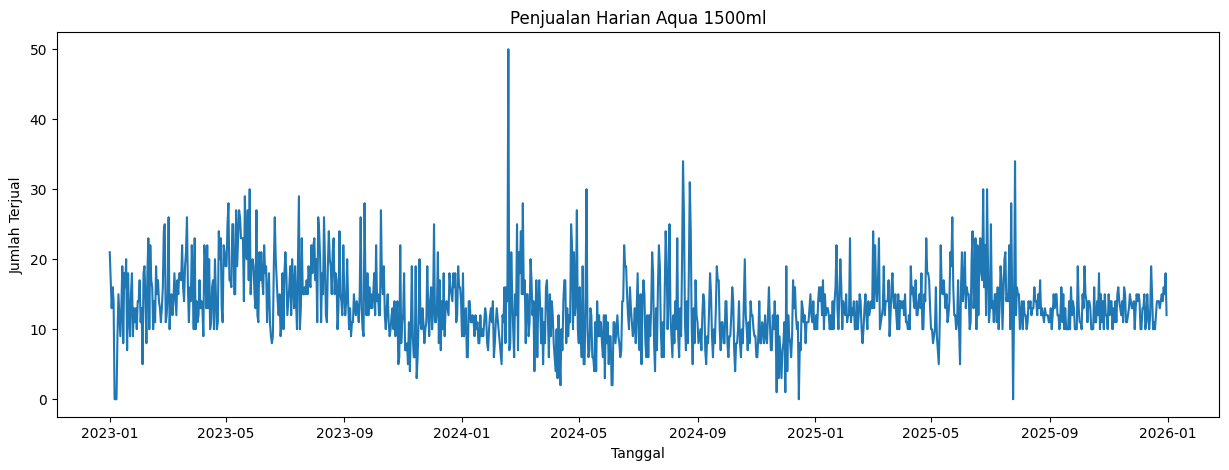

In [32]:
plt.figure(figsize=(15,5))

plt.plot(
    df['ds'],
    df['y']
)

plt.title("Penjualan Harian Aqua 1500ml")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Terjual")

plt.show()

5. ANALISIS PERTAHUN

In [33]:
df['tahun'] = df['ds'].dt.year

df.groupby('tahun')['y'].mean()

tahun
2023    15.301370
2024    11.466851
2025    13.739726
Name: y, dtype: float64

6. SPLIT DATA

In [34]:
train = df[
    df['ds'] < '2025-07-01'
]

test = df[
    df['ds'] >= '2025-07-01'
]

print("Train :", len(train))
print("Test :", len(test))

Train : 908
Test : 184


7. MEMBANGUN MODEL PROPHET

In [35]:
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True
)

model.fit(train)

10:07:27 - cmdstanpy - INFO - Chain [1] start processing
10:07:27 - cmdstanpy - INFO - Chain [1] done processing


8. PREDIKSI DATA TEST

In [36]:
future = model.make_future_dataframe(
    periods=len(test),
    freq='D'
)

forecast = model.predict(future)

In [37]:
#AMBIL PREDIKISI DATA TEST
pred_test = forecast[
    ['ds','yhat']
]

pred_test = pred_test[
    pred_test['ds'].isin(
        test['ds']
    )
]

9. EVALUASI MODEL

In [38]:
evaluation = test.merge(
    pred_test,
    on='ds'
)

In [47]:
mae = mean_absolute_error(
    evaluation['y'],
    evaluation['yhat']
)

rmse = np.sqrt(mean_squared_error(evaluation['y'], evaluation['yhat']))

smape = np.mean(
    (2 * np.abs(evaluation['y'] - evaluation['yhat']))
    /
    (np.abs(evaluation['y']) + np.abs(evaluation['yhat']))
    ) * 100

print("MAE :", round(mae))
print("RMSE :", round(rmse))
print("SMAPE :", round(smape,2), "%")

MAE : 3
RMSE : 4
SMAPE : 24.05 %


10. VISUALISASI AKTUAL VS PREDIKSI

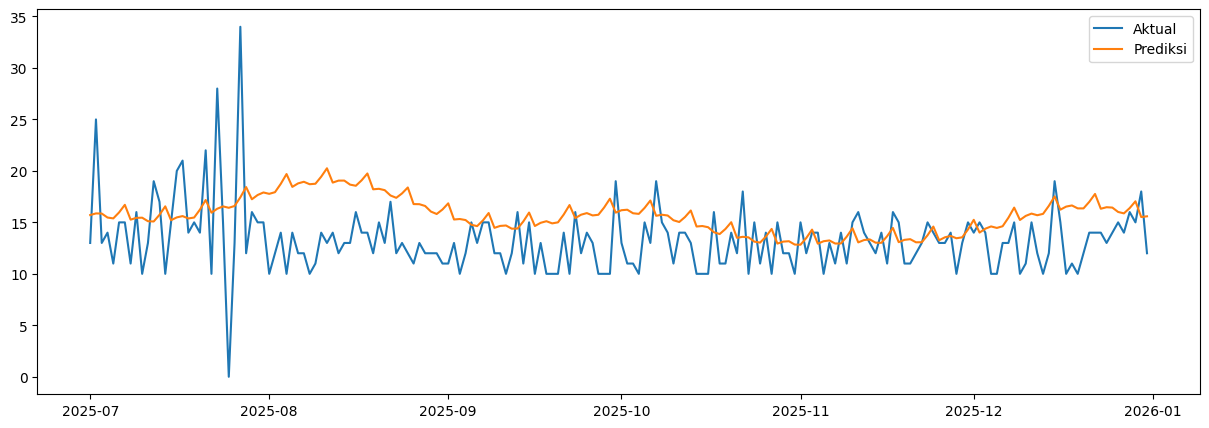

In [40]:
plt.figure(figsize=(15,5))

plt.plot(
    evaluation['ds'],
    evaluation['y'],
    label='Aktual'
)

plt.plot(
    evaluation['ds'],
    evaluation['yhat'],
    label='Prediksi'
)

plt.legend()

plt.show()

11. ANALISIS EROR TERBESAR

In [41]:
evaluation['error'] = abs(
    evaluation['y'] -
    evaluation['yhat']
)

evaluation.sort_values(
    'error',
    ascending=False
).head(20)

,ds,y,tahun,yhat,error
26,2025-07-27,34,2025,17.429943,16.570057
24,2025-07-25,0,2025,16.416391,16.416391
22,2025-07-23,28,2025,16.323231,11.676769
34,2025-08-04,10,2025,19.694239,9.694239
1,2025-07-02,25,2025,15.869009,9.130991
38,2025-08-08,10,2025,18.706139,8.706139
31,2025-08-01,10,2025,17.771526,7.771526
39,2025-08-09,11,2025,18.751336,7.751336
90,2025-09-29,10,2025,17.298733,7.298733
41,2025-08-11,13,2025,20.253931,7.253931


12. TRAINING FINAL MENGGUNAKAN SELURUH DATA

In [42]:
final_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True
)

final_model.fit(df[['ds','y']])

10:07:28 - cmdstanpy - INFO - Chain [1] start processing
10:07:28 - cmdstanpy - INFO - Chain [1] done processing


13. PERAMALAN 14 HARI KEDEPAN

In [43]:
future = final_model.make_future_dataframe(
    periods=14,
    freq='D'
)

forecast = final_model.predict(
    future
)

In [44]:
forecast_14 = forecast[
    ['ds','yhat']
].tail(14)

forecast_14

,ds,yhat
1092,2026-01-01,13.237321
1093,2026-01-02,12.720906
1094,2026-01-03,12.754619
1095,2026-01-04,13.397996
1096,2026-01-05,13.867286
1097,2026-01-06,12.618682
1098,2026-01-07,12.755909
1099,2026-01-08,12.478375
1100,2026-01-09,12.016450
1101,2026-01-10,12.116601


14. HITUNG REKOMENDASI PEMBELIAN

In [45]:
total_forecast = round(
    forecast_14['yhat'].sum()
)

print(
    "Kebutuhan stok 14 hari:",
    total_forecast
)

Kebutuhan stok 14 hari: 179


In [46]:
#TAMBAH SAFETY STOK 10%
stok_beli = round(
    total_forecast * 1.10
)

print(
    "Rekomendasi pembelian:",
    stok_beli
)

Rekomendasi pembelian: 197
